# Кластеризация текстовых документов: сравнение алгоритмов и проверка обобщения

**Набор данных:** пять тем 20 Newsgroups (`comp.graphics`, `rec.autos`, `sci.med`, `sci.space`, `talk.religion.misc`).  
**Часть A — исходное исследование:** TF-IDF (до 1 500 слов) → PCA/t-SNE/UMAP до 2D → K-Means/Agglomerative/GMM = **9 сочетаний**; оценка Silhouette и ARI, 30 повторов с 80%-ми подвыборками.  
**Часть B — расширение:** контрольный **TF-IDF + K-Means**, **TruncatedSVD (25, 50, 100) + K-Means**, **UMAP (10, 25, 50) + K-Means** с настройкой `n_neighbors` и `min_dist`; перекрёстные таблицы, чистота кластеров, типичные и пограничные тексты; отдельная процедура **train/validation/test**.

### Примечание к GitHub и воспроизводимости

Сохранённые графики и числа *исходного эксперимента* получены при предыдущем реальном запуске и доступны в GitHub без запуска. Код **30 повторов и расширенного протокола** пока не имеет рассчитанных выходов: среда подготовки не содержит загружаемого датасета. Чтобы показать и эти результаты в GitHub, открой файл в Google Colab → «Выполнить все» → скачай `.ipynb` **с сохранёнными выводами**. Числа в новых ячейках намеренно не придуманы.

**Исследовательская оговорка:** исходная часть использует все документы, включая их метки, для сравнения моделей. Новая часть заново разделяет тексты и изолирует *новый* подбор параметров от test, но это **не абсолютно невидимый ранее набор** за всю историю проекта. Для окончательного внешнего подтверждения понадобится новый независимый корпус. ARI — мера согласованности разбиений, **не accuracy**.


## 1. Данные и подготовка

`fetch_20newsgroups(subset='all', remove=('headers', 'footers', 'quotes'))` выбирает сообщения пяти тематических групп. Удаление заголовков, подписей и цитат снижает риск, что алгоритм отделяет темы по служебным особенностям сообщений, а не по содержанию. Полностью исключить косвенные подсказки этим нельзя.

`TfidfVectorizer` переводит тексты в числовые векторы: **TF** отражает частоту термина в документе, **IDF** уменьшает влияние слов, встречающихся во многих документах. `max_features=1500` ограничивает словарь, `min_df=5` исключает очень редкие термины, `max_df=0.8` — чрезмерно частые, `stop_words='english'` удаляет стандартные стоп-слова. После векторизации исключаются документы с нулевыми векторами.

В сохранённом исходном запуске: **4 568** загруженных документов → **4 377** ненулевых векторов размерности **1 500** (исключено 191, около 4,2%). Это свойства исходного выполненного запуска, а не вновь пересчитанные результаты.

**Ограничение:** TF-IDF преимущественно фиксирует лексическое совпадение; он не понимает синонимы, полисемию и глубокие семантические связи. Также нельзя по этим данным заключить, что ограничение словаря 1 500 оптимально.

In [ ]:
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

categories = [
    'sci.space',
    'sci.med',
    'rec.autos',
    'comp.graphics',
    'talk.religion.misc'
]

dataset = fetch_20newsgroups(
    subset='all',
    categories=categories,
    remove=('headers', 'footers', 'quotes'),
    random_state=42
)

texts = dataset.data
true_labels = dataset.target


vectorizer = TfidfVectorizer(
    max_features=1500,
    stop_words='english',
    min_df=5,
    max_df=0.8
)

X = vectorizer.fit_transform(texts)
feature_names = vectorizer.get_feature_names_out()

print(f"Размер итогового датасета: {X.shape[0]} объектов, {X.shape[1]} признаков")

In [ ]:
%pip install -q umap-learn

In [3]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

non_empty_mask = np.asarray(X.sum(axis=1)).ravel() > 0
X_clean = X[non_empty_mask]
y_clean = true_labels[non_empty_mask]
texts_clean = [texts[i] for i in range(len(texts)) if non_empty_mask[i]]

X_dense = X_clean.toarray()
print(f"Готово к работе: {X_dense.shape} текстов, {X_dense.shape} признаков")


pca_2d = PCA(n_components=2, random_state=42).fit_transform(X_dense)

tsne_2d = TSNE(n_components=2, metric='cosine', random_state=42).fit_transform(X_dense)

umap_2d = umap.UMAP(n_components=2, metric='cosine', random_state=42).fit_transform(X_dense)



Готово к работе: (4377, 1500) текстов, (4377, 1500) признаков


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## 2. Снижение размерности: как интерпретировать три проекции

- **PCA** сохраняет направления наибольшей дисперсии в линейной проекции. При сжатии 1 500 → 2 часть информации неизбежно теряется. Большой визуальный разброс ещё не гарантирует, что сохраняются тематические различия.
- **t-SNE** оптимизирует сохранение локальных отношений соседства. На графике близкие точки часто отражают сходство, но расстояния между далёкими группами и размеры «островков» **не следует трактовать буквально**. Поэтому красивое разделение на t-SNE само по себе не доказывает качество кластеризации.
- **UMAP** строит приближённый граф соседей и размещает точки в новом пространстве, стараясь сохранить его структуру. Форма, плотность и степень разделения групп зависят от параметров, в том числе `n_neighbors` и `min_dist`.

На графике точки окрашены **по истинной теме**, а не по предсказанному кластеру. Поэтому он показывает, удалось ли проекции расположить тексты одной тематики рядом, но не измеряет качество конкретного алгоритма кластеризации. Для этого нужны следующие метрики.

**Существенное ограничение дизайна:** все девять кластеризаций обучаются на **двумерных координатах**. Это честный эксперимент по сравнению *таких* пайплайнов, но не доказательство, что обучение кластеризации в 2D оптимально.

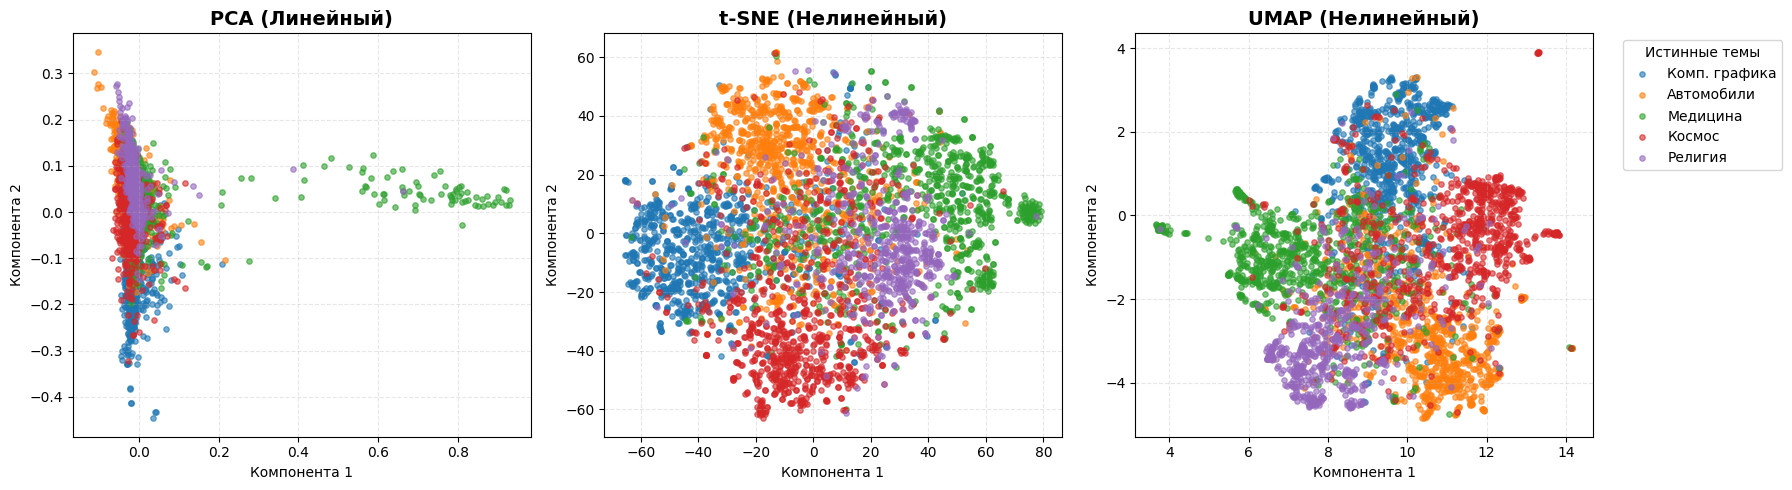

In [4]:
import matplotlib.pyplot as plt

# Названия наших 5 тем в правильном порядке (по алфавиту, как их загрузил sklearn)
target_names = [
    'Комп. графика',
    'Автомобили',
    'Медицина',
    'Космос',
    'Религия'
]

# Создаем полотно из 3 графиков в один ряд
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

datasets_2d = [
    (pca_2d, 'PCA (Линейный)'),
    (tsne_2d, 't-SNE (Нелинейный)'),
    (umap_2d, 'UMAP (Нелинейный)')
]

for ax, (data, title) in zip(axes, datasets_2d):
    # Рисуем точки для каждой из 5 тем своим цветом
    for class_id, class_name in enumerate(target_names):
        mask = (y_clean == class_id)
        ax.scatter(
            data[mask, 0],
            data[mask, 1],
            label=class_name,
            alpha=0.6,    # Прозрачность точек, чтобы видеть наложения
            s=15          # Размер точек
        )
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Компонента 1')
    ax.set_ylabel('Компонента 2')
    ax.grid(True, linestyle='--', alpha=0.3)

# Выносим общую легенду справа от графиков
axes[-1].legend(title='Истинные темы', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Наши 3 набора данных после понижения размерности
dr_methods = {
    'PCA': pca_2d,
    't-SNE': tsne_2d,
    'UMAP': umap_2d
}

results = []

# Перебираем каждый метод сжатия (3 шт.) и каждый алгоритм кластеризации (3 шт.)
for dr_name, X_embedded in dr_methods.items():

    # Создаем 3 модели кластеризации (ищем 5 кластеров)
    clusterers = {
        'K-Means': KMeans(n_clusters=5, random_state=42, n_init=10),
        'Agglomerative': AgglomerativeClustering(n_clusters=5),
        'GMM': GaussianMixture(n_components=5, random_state=42)
    }

    for clust_name, model in clusterers.items():
        # Обучаем модель и получаем номера кластеров (от 0 до 4)
        pred_labels = model.fit_predict(X_embedded)

        # Считаем метрики качества
        sil = silhouette_score(X_embedded, pred_labels)
        ari = adjusted_rand_score(y_clean, pred_labels)

        results.append({
            'Метод сжатия (DR)': dr_name,
            'Кластеризация': clust_name,
            'Silhouette (плотность)': round(sil, 3),
            'ARI (точность тем)': round(ari, 3)
        })

# Собираем все результаты в красивую таблицу и сортируем по точности (ARI)
df_results = pd.DataFrame(results).sort_values(by='ARI (точность тем)', ascending=False)
print(df_results.to_string(index=False))

Метод сжатия (DR) Кластеризация  Silhouette (плотность)  ARI (точность тем)
             UMAP       K-Means                   0.416               0.394
            t-SNE       K-Means                   0.391               0.377
            t-SNE           GMM                   0.375               0.359
             UMAP           GMM                   0.384               0.357
            t-SNE Agglomerative                   0.334               0.305
             UMAP Agglomerative                   0.359               0.302
              PCA       K-Means                   0.446               0.108
              PCA           GMM                   0.347               0.105
              PCA Agglomerative                   0.420               0.104


## 3. Интерпретация основного эксперимента: все девять сочетаний

### Что именно означают метрики

**Silhouette** показывает, насколько объекты в рассматриваемом пространстве ближе к своему кластеру, чем к соседнему. Типичные значения лежат между −1 и 1; больше обычно означает более выраженную геометрическую отделённость. Здесь метрика посчитана **в соответствующей 2D-проекции**. Сравнивать её между PCA, t-SNE и UMAP как единую «шкалу качества смысловой кластеризации» нельзя: методы меняют геометрию и плотности по-разному.

**ARI (Adjusted Rand Index)** сравнивает найденные кластеры с пятью известными тематическими метками. **1** — полное совпадение разбиений, **0** — уровень, ожидаемый при случайной согласованности с поправкой на случайные совпадения; возможны отрицательные значения. **ARI не является accuracy:** например, ARI = 0,394 не значит «39,4% текстов классифицированы правильно».

### Результаты сохранённого запуска

| Метод снижения размерности | Метод кластеризации | Silhouette в 2D | ARI по темам |
|:--|:--|--:|--:|
| **UMAP** | **K-Means** | 0,416 | **0,394** |
| t-SNE | K-Means | 0,391 | 0,377 |
| t-SNE | GMM | 0,375 | 0,359 |
| UMAP | GMM | 0,384 | 0,357 |
| t-SNE | Agglomerative | 0,334 | 0,305 |
| UMAP | Agglomerative | 0,359 | 0,302 |
| PCA | K-Means | **0,446** | 0,108 |
| PCA | GMM | 0,347 | 0,105 |
| PCA | Agglomerative | 0,420 | 0,104 |

*Числа взяты из фактического вывода ячейки сравнения в исходном ноутбуке. Это результаты одного основного запуска, а не средние по 30 повторам.*

### Подробный разбор каждой комбинации

1. **UMAP + K-Means — Silhouette 0,416; ARI 0,394.** Самое высокое соответствие пяти известным темам среди девяти сочетаний. На 2D-проекции UMAP K-Means удаётся найти разбиение, относительно близкое к смысловым категориям. При этом ARI далёк от 1: заметное смешение тем остаётся, а результат одного запуска не доказывает устойчивого преимущества.
2. **t-SNE + K-Means — Silhouette 0,391; ARI 0,377.** Второе место по тематической согласованности. Разница ARI с UMAP + K-Means составляет всего **0,017**: по одному запуску нельзя считать её убедительным превосходством UMAP. Результат показывает, что локальная структура t-SNE может быть полезна для компактных групп, распознаваемых K-Means.
3. **t-SNE + GMM — Silhouette 0,375; ARI 0,359.** Выглядит немного слабее K-Means на той же t-SNE-проекции. GMM моделирует смесь гауссовских распределений и допускает эллипсоидальные компоненты. Более гибкая форма кластера здесь **не принесла улучшения ARI**, хотя она может быть полезной на других данных.
4. **UMAP + GMM — Silhouette 0,384; ARI 0,357.** Тематическое соответствие близко к t-SNE + GMM, но ниже UMAP + K-Means на **0,037** ARI. У этих компонентов другая геометрическая модель: вероятностная модель GMM, в отличие от K-Means, не гарантирует лучшее соответствие темам после UMAP.
5. **t-SNE + Agglomerative — Silhouette 0,334; ARI 0,305.** На t-SNE это худшее из трёх рассматриваемых разбиений по ARI. Метод Уорда последовательно объединяет группы, минимизируя прирост внутрикластерной суммы квадратов; его решения чувствительны к форме облаков и геометрии проекции.
6. **UMAP + Agglomerative — Silhouette 0,359; ARI 0,302.** Близко к предыдущему по ARI, но существенно уступает UMAP + K-Means. Это означает лишь, что иерархический метод с текущими параметрами хуже соответствует эталонным темам в построенной 2D-проекции.
7. **PCA + K-Means — Silhouette 0,446; ARI 0,108.** **Самый важный контрпример проекта:** лучший Silhouette и одновременно слабая тематическая согласованность. Кластеры в 2D-пространстве PCA геометрически отделены, но **не совпадают со смысловыми классами**. Значит, нельзя выбирать модель только по Silhouette без учёта исследовательской цели.
8. **PCA + GMM — Silhouette 0,347; ARI 0,105.** Содержательно почти столь же низкая согласованность с темами, что у PCA + K-Means. Смена модели границ кластеров не компенсировала информацию о темах, не сохранённую двумя главными компонентами.
9. **PCA + Agglomerative — Silhouette 0,420; ARI 0,104.** Относительно высокая геометрическая разделённость вместе с низким ARI подтверждает ту же тенденцию: разбиение в плоскости PCA отражает структуру разброса данных, но почти не воспроизводит заданные темы.

### Обобщённый вывод

В **этом** эксперименте методы, учитывающие нелинейную структуру (**t-SNE и UMAP**), дают существенно более высокие ARI, чем двухкомпонентная PCA. Для PCA проблема может быть именно в резком сжатии до 2D, а не в принципиальной непригодности линейных методов. Среди алгоритмов кластеризации **K-Means** лучше других в t-SNE и UMAP для данных параметров. **Победитель одного запуска — UMAP + K-Means**, но для более сильного вывода требуется оценка разброса по повторам, приведённая далее.


## 4. Проверка повторяемости результатов — 30 подвыборок × 9 комбинаций

Для **каждого** из 30 повторов берётся новая случайная подвыборка из **80%** документов, **одинаковая для всех девяти пайплайнов внутри данного повтора**. Методы снижения размерности обучаются заново, затем заново выполняются K-Means, Agglomerative и GMM. Это **90 новых обучений проекции** и **270 кластеризаций** (помимо основного эксперимента на всех данных).

Рассчитываются **два разных ARI**:

1. **ARI к истинным темам (`ARI_темы`)** — насколько кластеры повторного запуска совпадают с исходными категориями выбранных текстов. Это *качество по внешней разметке*.
2. **ARI к полному разбиению (`ARI_устойчивость`)** — насколько кластеры повторного запуска совпадают с предсказанными кластерами базового запуска, **только на тех же выбранных документах**. Это *стабильность разбиения при смене состава данных и случайного состояния*, **не** качество относительно тем.

Среднее и стандартное отклонение показывают типичный уровень и разброс значений между подвыборками. **Среднее ± стандартное отклонение — не 95%-й доверительный интервал.** Подвыборки перекрываются, результаты зависимы; данные не дают оснований проводить формальный тест превосходства алгоритма без отдельного дизайна эксперимента.

**Важно для GitHub:** этот блок **не содержит сохранённых результатов 30 повторов** в переданной версии файла: исходные 20 Newsgroups недоступны для вычисления в этой среде. После запуска ноутбука в Colab код ниже автоматически сформирует таблицу, два графика и разбор всех девяти сочетаний.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
import umap

# Один и тот же набор документов в каждом повторе для всех 9 комбинаций.
N_RUNS = 30                 # Для пробного запуска можно временно поставить 3.
SAMPLE_FRACTION = 0.80      # Каждый раз берём 80% документов без повторений.
RANDOM_STATE = 42
N_CLUSTERS = 5


def cluster_predict(name, coordinates, seed):
    """Новые экземпляры моделей при каждом запуске."""
    if name == 'K-Means':
        return KMeans(n_clusters=N_CLUSTERS, random_state=seed,
                      n_init=10).fit_predict(coordinates)
    if name == 'Agglomerative':
        return AgglomerativeClustering(n_clusters=N_CLUSTERS).fit_predict(coordinates)
    if name == 'GMM':
        return GaussianMixture(n_components=N_CLUSTERS,
                               random_state=seed).fit_predict(coordinates)
    raise ValueError(f'Неизвестный алгоритм кластеризации: {name}')


CLUSTER_NAMES = ('K-Means', 'Agglomerative', 'GMM')

# Эталоны: разбиения *всех* документов каждой из девяти комбинаций.
# dr_methods содержит уже вычисленные на всех данных проекции из предыдущей ячейки.
reference_labels = {
    (dr_name, cluster_name): cluster_predict(cluster_name, X_all, RANDOM_STATE)
    for dr_name, X_all in dr_methods.items()
    for cluster_name in CLUSTER_NAMES
}

# Сохраняем переменную из первоначального варианта ноутбука:
# она используется ниже для интерпретации кластеров UMAP + K-Means.
base_labels = reference_labels[('UMAP', 'K-Means')]

rng = np.random.default_rng(RANDOM_STATE)
n_samples = len(y_clean)
sample_size = int(SAMPLE_FRACTION * n_samples)
if not 0 < sample_size < n_samples:
    raise ValueError('Некорректное SAMPLE_FRACTION: нужна непустая подвыборка.')

runs = []
print(f'Проверяем 9 комбинаций: {N_RUNS} повторов × 80% данных.')
print('Метрики: ARI к истинным темам и ARI устойчивости к полному разбиению.\n')

for run in range(N_RUNS):
    # Разные выборки, но одинаковые для всех методов внутри каждого повтора.
    idx = np.sort(rng.choice(n_samples, size=sample_size, replace=False))
    seed = RANDOM_STATE + run + 1
    X_subset = X_dense[idx]

    # ВАЖНО: DR переобучается на каждой подвыборке; каждая новая
    # проекция используется сразу для трёх алгоритмов кластеризации.
    reduced = {
        'PCA': PCA(n_components=2, random_state=seed).fit_transform(X_subset),
        't-SNE': TSNE(n_components=2, metric='cosine',
                     random_state=seed).fit_transform(X_subset),
        'UMAP': umap.UMAP(n_components=2, metric='cosine',
                          random_state=seed, n_jobs=1).fit_transform(X_subset),
    }

    for dr_name, X_reduced in reduced.items():
        for cluster_name in CLUSTER_NAMES:
            predicted = cluster_predict(cluster_name, X_reduced, seed)
            runs.append({
                'Запуск': run + 1,
                'DR': dr_name,
                'Кластеризация': cluster_name,
                'ARI_темы': adjusted_rand_score(y_clean[idx], predicted),
                # Метки сравниваются на одних и тех же документах!
                'ARI_устойчивость': adjusted_rand_score(
                    reference_labels[(dr_name, cluster_name)][idx], predicted
                ),
            })
    print(f'Повтор {run + 1:02d}/{N_RUNS} завершён')

# Полные результаты 270 отдельных экспериментов.
stability_runs = pd.DataFrame(runs)

# Итог по каждой из девяти комбинаций.
stability_summary = (
    stability_runs
    .groupby(['DR', 'Кластеризация'], as_index=False)
    .agg(
        n_runs=('ARI_темы', 'size'),
        ARI_темы_среднее=('ARI_темы', 'mean'),
        ARI_темы_std=('ARI_темы', 'std'),
        ARI_устойчивость_среднее=('ARI_устойчивость', 'mean'),
        ARI_устойчивость_std=('ARI_устойчивость', 'std'),
    )
    .sort_values('ARI_темы_среднее', ascending=False)
    .reset_index(drop=True)
)

print('\n=== 30 ПОВТОРОВ: КАЧЕСТВО И УСТОЙЧИВОСТЬ ===')
print(stability_summary.round(3).to_string(index=False))

# Два разных показателя — рядом, но на разных графиках.
labels_for_plot = (stability_summary['DR'] + ' + ' +
                   stability_summary['Кластеризация'])
y_pos = np.arange(len(stability_summary))
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
axes[0].barh(y_pos, stability_summary['ARI_темы_среднее'],
             xerr=stability_summary['ARI_темы_std'], capsize=3)
axes[0].set_title('Качество по истинным темам (ARI)')
axes[0].set_xlabel('Среднее ± стандартное отклонение')
axes[1].barh(y_pos, stability_summary['ARI_устойчивость_среднее'],
             xerr=stability_summary['ARI_устойчивость_std'], capsize=3)
axes[1].set_title('Устойчивость к полному разбиению (ARI)')
axes[1].set_xlabel('Среднее ± стандартное отклонение')
axes[0].set_yticks(y_pos, labels_for_plot)
axes[0].invert_yaxis()
for ax in axes:
    ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

# При желании сохранить таблицы в Colab:
# stability_runs.to_csv('stability_all_270_runs.csv', index=False)
# stability_summary.to_csv('stability_summary_9_pipelines.csv', index=False)


## 5. Автоматический подробный разбор **фактически полученных** 30 повторов

Ниже — код, который после успешного завершения предыдущей ячейки **по рассчитанным значениям** автоматически создаёт отдельную текстовую интерпретацию **каждого из девяти пайплайнов**, включая:

- средний ARI к реальным категориям и его стандартное отклонение;
- средний ARI устойчивости относительно полного разбиения и его стандартное отклонение;
- сравнение с результатом базового полного запуска;
- содержательное объяснение того, почему особенности PCA / t-SNE / UMAP и K-Means / Agglomerative / GMM могут отражаться в полученном результате;
- общие выводы и ограничения.

Вывод будет сохранён в `.ipynb` при повторном сохранении ноутбука **после исполнения**. До вычисления 30 повторов здесь намеренно **нет чисел**, чтобы не выдавать прогноз за экспериментальный результат.

In [ ]:
from IPython.display import display, Markdown

# Эта интерпретация строится ТОЛЬКО по фактически посчитанным 30 повторам.
assert len(stability_runs) == N_RUNS * 9, (
    f'Ожидалось {N_RUNS * 9} строк, получено {len(stability_runs)}')

base = df_results.rename(columns={
    'Метод сжатия (DR)': 'DR',
    'Кластеризация': 'Кластеризация',
    'ARI (точность тем)': 'ARI_полная_выборка',
    'Silhouette (плотность)': 'Silhouette_полная_выборка',
})
report_df = stability_summary.merge(
    base[['DR', 'Кластеризация', 'ARI_полная_выборка',
          'Silhouette_полная_выборка']],
    on=['DR', 'Кластеризация'], how='left', validate='one_to_one'
)


def fmt(x):
    return f'{x:.3f}'.replace('.', ',')


report = [
    '# Подробная интерпретация 30 повторных экспериментов',
    '',
    f'Проанализированы **{N_RUNS} подвыборок × 9 комбинаций = {len(stability_runs)} кластеризаций**.',
    'Обе приведённые оценки ARI рассчитаны на одинаковых объектах внутри каждого повтора.',
    '',
    '### 1. Ранжирование по среднему ARI к истинным темам',
]

leader = report_df.iloc[0]
runner = report_df.iloc[1]
report.extend([
    f'Лидер по среднему ARI к темам — **{leader.DR} + {leader.Кластеризация}**: '
    f'**{fmt(leader.ARI_темы_среднее)} ± {fmt(leader.ARI_темы_std)}** '
    '(среднее ± стандартное отклонение между подвыборками).',
    f'Второе место — **{runner.DR} + {runner.Кластеризация}** '
    f'({fmt(runner.ARI_темы_среднее)} ± {fmt(runner.ARI_темы_std)}). '
    'Разницу в средних **не следует объявлять статистически значимой** без отдельного анализа.',
    '',
    '### 2. Разбор каждой из девяти комбинаций',
])

for row in report_df.itertuples(index=False):
    name = f'{row.DR} + {row.Кластеризация}'
    delta = row.ARI_темы_среднее - row.ARI_полная_выборка
    diff = 'выше' if delta > 0.005 else ('ниже' if delta < -0.005 else 'примерно на уровне')
    description = {
        'PCA': 'Линейная 2D-проекция сохраняет направления максимальной дисперсии, но не обязана отделять темы.',
        't-SNE': 'Локальные соседства представлены нелинейно; расстояния и плотности областей сильно зависят от визуализационной геометрии.',
        'UMAP': 'Нелинейная проекция приближённо сохраняет граф соседства; разделение областей зависит от настроек UMAP.',
    }[row.DR]
    cl_description = {
        'K-Means': 'Алгоритм группирует точки вокруг центров, предпочитая относительно компактные области.',
        'Agglomerative': 'Иерархическое объединение с критерием Уорда чувствительно к геометрии пространства.',
        'GMM': 'Смесь гауссовских распределений допускает вероятностную принадлежность и эллипсоидальные компоненты.',
    }[row.Кластеризация]

    report.extend([
        f'**{name}.**  ',
        f'- **Тематическое качество:** ARI = **{fmt(row.ARI_темы_среднее)} ± '
        f'{fmt(row.ARI_темы_std)}**. Чем выше среднее, тем больше согласованность '
        'с известными темами. Стандартное отклонение показывает изменчивость между подвыборками.',
        f'- **Устойчивость:** ARI = **{fmt(row.ARI_устойчивость_среднее)} ± '
        f'{fmt(row.ARI_устойчивость_std)}** относительно базового разбиения на совпадающих '
        'документах. Высокая устойчивость не равнозначна высокому качеству по темам.',
        f'- **Сравнение с полным набором:** ARI полного запуска = '
        f'{fmt(row.ARI_полная_выборка)}, среднее по подвыборкам {diff} '
        f'(разность {fmt(delta)}). Это описательное сравнение: состав и размер данных различны.',
        f'- **Что означает результат:** {description} {cl_description}',
        '',
    ])

report.extend([
    '### 3. Что говорит разброс результатов',
    '',
    'Сравнивай **стандартные отклонения ARI к темам**: больший разброс означает, '
    'что при данном протоколе результат сильнее зависит от выбранных документов и seed. '
    'Разброс качества и разброс устойчивости нельзя подменять друг другом.',
])
most_variable = report_df.loc[report_df['ARI_темы_std'].idxmax()]
least_variable = report_df.loc[report_df['ARI_темы_std'].idxmin()]
most_stable = report_df.loc[report_df['ARI_устойчивость_среднее'].idxmax()]
report.extend([
    f'Наибольший наблюдаемый разброс тематического ARI: '
    f'**{most_variable.DR} + {most_variable.Кластеризация}** '
    f'(std = {fmt(most_variable.ARI_темы_std)}).',
    f'Наименьший наблюдаемый разброс тематического ARI: '
    f'**{least_variable.DR} + {least_variable.Кластеризация}** '
    f'(std = {fmt(least_variable.ARI_темы_std)}).',
    f'Максимальная средняя устойчивость относительно базового разбиения: '
    f'**{most_stable.DR} + {most_stable.Кластеризация}** '
    f'(ARI = {fmt(most_stable.ARI_устойчивость_среднее)}).',
    '',
    '### 4. Методологические ограничения и финальный вывод',
    '',
    '- Все методы кластеризуют **двухмерные** представления — преимущество в этих условиях '
    'не обязано сохраняться на исходных TF-IDF или на 25–100 компонентах.',
    '- Сравнения не имеют независимого test-набора, а лучшие сочетания выбираются '
    'по известным темам: это исследовательская модельная селекция, не оценка '
    'обобщающей способности на ранее невидимых документах.',
    '- Для строгого вывода добавить baseline K-Means на TF-IDF, TruncatedSVD + K-Means, '
    'контроль параметров, отдельную оценку качества и проверки повторяемости.',
    '',
    f'**Итог по этому протоколу:** наиболее высокий средний ARI к темам показал '
    f'**{leader.DR} + {leader.Кластеризация}**, '
    f'но превосходство следует формулировать как **наблюдаемое на этих 30 подвыборках**, '
    'а не как универсально доказанное.',
])

display(Markdown('\n'.join(report)))


## 6. Семантическая интерпретация пяти кластеров выбранного пайплайна

В сохранённом исходном эксперименте для интерпретации выбран **UMAP + K-Means** (лучший ARI в основном сравнении). Средние TF-IDF по каждому кластеру позволяют получить **описание наиболее характерной лексики**, а не проверку его чистоты. Номера кластеров произвольны: `cluster 0` не означает «категория 0».

| Кластер | Документов | Характерные слова (из исходного выполнения) | Интерпретация |
|:--:|--:|:--|:--|
| 0 | 610 | `msg`, `doctor`, `disease`, `pain`, `medical` | В основном медицинская лексика: болезни, пациенты, лечение; `msg` может быть неоднозначным маркером контекста. |
| 1 | 775 | `space`, `nasa`, `launch`, `orbit`, `shuttle` | Лексика космонавтики: космические миссии, орбиты и запуски. |
| 2 | 781 | `car`, `cars`, `engine`, `oil`, `ford` | Автомобили, двигатели, техническое обслуживание. |
| 3 | 1 077 | `graphics`, `image`, `file`, `software`, `program` | Компьютерная графика, форматы файлов и программное обеспечение. |
| 4 | 1 134 | `god`, `jesus`, `people`, `good`, `think` | Религиозные обсуждения и сопутствующие общие рассуждения. |

**Как читать эту таблицу.** Пять групп действительно получили тематически узнаваемую лексику. Однако это **не доказывает**, что каждый кластер состоит преимущественно из соответствующего истинного класса: для такого вывода требуется таблица перекрёстного распределения `cluster × true_label`, доли классов и ошибка смешения тем.

**Почему примеры могут выглядеть странно.** Код берёт **первый** документ подходящей длины, а не самый близкий к центру кластера. Поэтому пример в религиозном кластере в сохранённом выводе не обязательно содержит слова о религии. Это недостаток алгоритма выбора примеров, а не автоматическое доказательство неверной кластеризации.

**Что улучшить:** выбирать характерный документ по расстоянию до центроида кластера, дополнить долями пяти реальных тем, долями редких/общих слов и ручной проверкой нескольких документов в каждой группе.

In [8]:
import numpy as np

# Получаем названия всех 1500 слов-признаков из векторизатора
terms = vectorizer.get_feature_names_out()

print("=== ПРАКТИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ КЛАСТЕРОВ (UMAP + K-Means) ===\n")

for cluster_id in range(5):
    # Находим индексы всех текстов, попавших в текущий кластер
    cluster_mask = (base_labels == cluster_id)
    cluster_size = np.sum(cluster_mask)

    # Считаем средний вес TF-IDF каждого из 1500 слов внутри этого кластера
    mean_tfidf = X_dense[cluster_mask].mean(axis=0)

    # Сортируем слова по убыванию важности и берем топ-10
    top_indices = mean_tfidf.argsort()[::-1][:10]
    top_words = [terms[idx] for idx in top_indices]

    print(f"Кластер №{cluster_id} (документов: {cluster_size}):")
    print(f"  Ключевые слова: {', '.join(top_words)}")

    # Берем первый попавшийся не слишком длинный текст из этого кластера для примера
    cluster_texts = [texts_clean[i] for i in range(len(texts_clean)) if cluster_mask[i]]
    sample_text = next((t.strip().replace('\n', ' ') for t in cluster_texts if 60 < len(t.strip()) < 300), cluster_texts[0][:150])
    print(f"  Пример текста: «{sample_text[:180]}...»\n")


=== ПРАКТИЧЕСКАЯ ИНТЕРПРЕТАЦИЯ КЛАСТЕРОВ (UMAP + K-Means) ===

Кластер №0 (документов: 610):
  Ключевые слова: msg, doctor, disease, pain, don, food, gordon, people, medical, patients
  Пример текста: «My comments about the Feingold Diet have no relevance to your daughter's purported FrostedFlakes-related seizures.  I can't imagine why you included it....»

Кластер №1 (документов: 775):
  Ключевые слова: space, nasa, launch, orbit, shuttle, moon, like, just, earth, edu
  Пример текста: «... I believe that my former employer Hughes Aircraft Company has a working Ion  Propulsion system for satellites....»

Кластер №2 (документов: 781):
  Ключевые слова: car, cars, engine, just, like, oil, ford, new, dealer, don
  Пример текста: «no, but somebody's dropped a ford 302 V-8 into the miata, somewhat reminiscent of the shelby cobra.  the car's obviously not as nimble as before, but it's supposed to have a near 5...»

Кластер №3 (документов: 1077):
  Ключевые слова: thanks, graphics, know, imag

## 7. Как читать сетку из 9 диаграмм

Каждая строка сетки использует **одну и ту же проекцию** (PCA / t-SNE / UMAP); каждый столбец — **разные правила деления тех же точек** (K-Means / Agglomerative / GMM). В отличие от графиков раздела 2, здесь цвета показывают **найденные алгоритмом кластеры**, а не реальные классы.

При анализе сравнивайте:

1. **Форму границ:** K-Means образует области вокруг центров, GMM допускает эллипсоидальные компоненты, Agglomerative зависит от истории объединения групп.
2. **Перекрытие и локальные сгустки:** визуальное разделение помогает понять механизм, но не заменяет ARI.
3. **Изменение раскраски при фиксированной проекции:** если две модели делят одни и те же точки по-разному, различие связано с методом кластеризации; между строками меняется **сама геометрия** данных.

**Нельзя:** приравнивать размер облака на t-SNE/UMAP к числу «важных» тем или расстояние между «островками» — к объективному семантическому расстоянию.

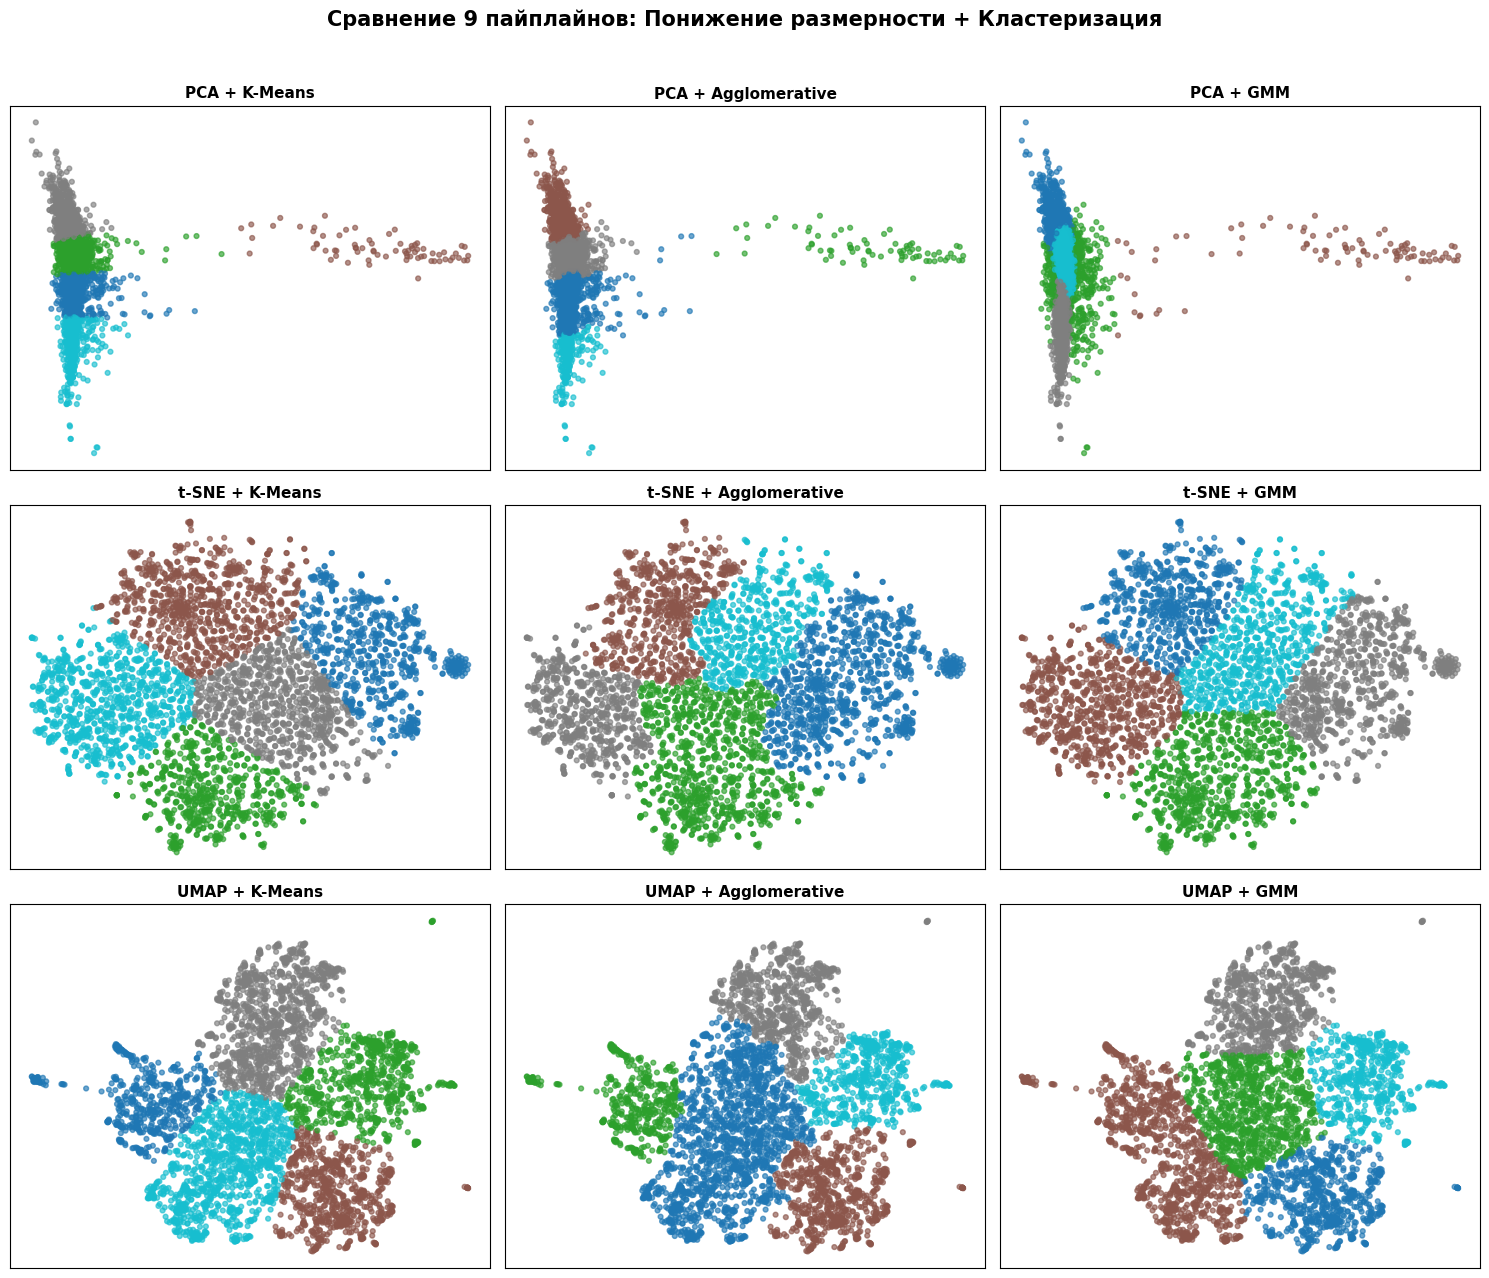

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
fig.suptitle('Сравнение 9 пайплайнов: Понижение размерности + Кластеризация', fontsize=15, fontweight='bold')

dr_list = [('PCA', pca_2d), ('t-SNE', tsne_2d), ('UMAP', umap_2d)]
clust_names = ['K-Means', 'Agglomerative', 'GMM']

for i, (dr_name, X_emb) in enumerate(dr_list):
    for j, c_name in enumerate(clust_names):
        ax = axes[i, j]

        if c_name == 'K-Means':
            pred = KMeans(n_clusters=5, random_state=42, n_init=10).fit_predict(X_emb)
        elif c_name == 'Agglomerative':
            pred = AgglomerativeClustering(n_clusters=5).fit_predict(X_emb)
        else:
            pred = GaussianMixture(n_components=5, random_state=42).fit_predict(X_emb)

        ax.scatter(X_emb[:, 0], X_emb[:, 1], c=pred, cmap='tab10', alpha=0.65, s=12)
        ax.set_title(f"{dr_name} + {c_name}", fontsize=11, fontweight='bold')
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## 8. Итоги исходной части и переход к новому протоколу

**Что действительно подтверждено сохранённым основным запуском:** для пяти тем 20 Newsgroups комбинация **UMAP + K-Means** показала наибольшее соответствие меткам (**ARI 0,394**); **PCA + K-Means** имела наибольшую геометрическую компактность/разделённость (**Silhouette 0,446**), но слабую тематическую согласованность (**ARI 0,108**). Это наглядно демонстрирует расхождение внутренней и внешней метрик кластеризации.

**Что можно будет утверждать после 30 повторов:** какие комбинации имеют более высокое **среднее** соответствие меткам при данном протоколе 80%-ных подвыборок; какие сильнее зависят от состава выборки; какие чаще воспроизводят своё исходное разбиение. Различия в средних не становятся автоматически статистически значимыми.

**Ограничения исходной части (до расширения ниже):** кластеризация в 2D, отсутствие контроля TF-IDF без проекции, отсутствие TruncatedSVD на 25–100 компонентах, отсутствие подбора параметров, использование одних и тех же известных категорий для выбора лучшего решения и его оценки, ограниченная интерпретация структуры ошибок кластеров.

**Эксперименты, реализованные в следующих разделах:**

1. Сравнить с K-Means на исходном нормализованном TF-IDF и TruncatedSVD (`n_components` 25, 50, 100) + K-Means.
2. Проверить UMAP с 10–50 измерениями отдельно от 2D-визуализации и варьировать `n_neighbors`/`min_dist`.
3. Добавить перекрёстную таблицу `истинная тема × кластер`, распределения чистоты кластеров, типичные и пограничные документы.
4. Использовать строго определённый протокол настройки параметров и итоговой независимой оценки.

### Как получить GitHub-просмотр **всех** рассчитанных ячеек

1. Открой ноутбук в **Google Colab** с подключённым интернетом. Там загрузятся 20 Newsgroups и пакет `umap-learn`.
2. Запусти **Среда выполнения → Выполнить все**. Выполнение 30 повторов t-SNE и UMAP на ~3 500 документах ресурсоёмко.
3. После окончания сохрани `.ipynb` **с выводами ячеек** (например, «Файл → Скачать → Скачать файл .ipynb» или сохранение копии в GitHub).
4. Загрузи **полученный после исполнения файл** на GitHub. GitHub отображает сохранённые в notebook графики, таблицы и Markdown без отдельного выполнения Python.

**Прозрачность результатов этой версии:** результаты основного запуска — сохранённые, реальные; 30 повторов — код и автоматический интерпретатор есть, но запуск ещё не состоялся.

**Далее начинается отдельный протокол с train/validation/test.** Его test-метрики не следует смешивать с исходным ARI на полном наборе, поскольку обучающие данные, словарь TF-IDF и процедура отбора отличаются.


---

## 9. Строгий протокол обучения, подбора параметров и итоговой оценки

### Исследовательский план (фиксируется **до** просмотра новых результатов)

1. **Подготовка:** берём исходные тексты и удаляем только пустые и *точные* дубли по нормализованному написанию (нижний регистр, схлопывание пробелов). Это уменьшается риск повторения одного текста между частями; почти одинаковые/перепечатанные сообщения всё ещё возможны. Старый эксперимент не меняем.
2. **Разделение:** случайные 60% **train**, 20% **validation**, 20% **test** с `random_state=2026`. Здесь разделяем **до TF-IDF**, без стратификации и без обращения к темам. Размер кластера **K=5 фиксирован заранее** согласно постановке задачи, а не подбирается по test.
3. **Отбор моделей:** TF-IDF (`max_features=1500`, `min_df=5`, `max_df=0.8`, L2 по умолчанию) обучается **только на train**. Все методы снижения размерности и K-Means обучаются на train. На validation лишь предсказываем кластеры. Тексты с нулевыми TF-IDF-векторами исключаем и явно считаем их долю.
4. **Кандидаты:** 1 × исходный нормализованный TF-IDF; 3 × TruncatedSVD (`25, 50, 100` компонент, с L2-нормализацией результата); 12 × UMAP (`10, 25, 50` измерений, `n_neighbors = 15/50`, `min_dist = 0.0/0.3`). **Итого 16 конфигураций**. У UMAP многомерные представления служат *именно для кластеризации*, а не для построения 2D-графика.
5. **Повторы настройки:** каждый кандидат оценивается с **двумя заранее зафиксированными `random_state`**. Основная метрика отбора — **средний Silhouette на validation в едином исходном TF-IDF-пространстве, с косинусным расстоянием**. Чтобы не выбирать вырожденное решение, запрещаем разбиения, где на validation отсутствует кластер или кластер содержит менее 1% объектов (минимум 5). Если равенство — предпочитаем меньший разброс, затем лексикографический порядок названий. **Известные темы и ARI при выборе не используются.**
6. **Однократный test:** выбираем лучшую конфигурацию; заново обучаем **весь пайплайн** (включая TF-IDF) на **train + validation**, один раз предсказываем отложенный test и рассчитываем **ARI, AMI, V-measure, Silhouette**, чистоту кластеров и примеры документов. После этого **не перенастраиваем модель по test**.

**Почему не включаем t-SNE и Agglomerative в этот рейтинг?** Стандартный `sklearn.TSNE` не предоставляет `.transform()` для новых текстов, а `AgglomerativeClustering` — `.predict()` для новых объектов. Они остаются в исходном *разведочном* сравнении; новый отложенный протокол сравнивает только корректно переносимые на test пайплайны. GMM не запрещён, но здесь сознательно фиксируем K-Means, чтобы изолировать эффект представления текста.

**Важная научная граница:** поскольку предыдущие эксперименты уже анализировали весь 20 Newsgroups и использовали истинные темы при выборе исследовательских решений, test здесь является *независимым относительно нового цикла подбора*, но не полностью «не виденным ранее» на уровне всего проекта. Для финального внешнего доказательства требуется новый корпус либо изначально скрытая выборка.


In [ ]:
# Эксперимент B.1 — чистый split ДО TF-IDF (не используем X_clean / X_dense исходной части).
import hashlib
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             adjusted_mutual_info_score, v_measure_score)
from IPython.display import display, Markdown

PROTOCOL_SEED = 2026
K_FIXED = 5
TFIDF_PARAMS = dict(max_features=1500, min_df=5, max_df=0.8,
                    stop_words='english', norm='l2')
SEEDS_SELECTION = (2026, 2042)  # Повторяем каждую конфигурацию, НЕ заглядывая в test.
VALIDATION_SIL_SAMPLE = 750     # Одинаковый размер/seed подвыборки для метрики.

# Удаление только точных дублей после унификации пробелов и регистра.
# Нельзя включать тематическую метку в ключ — одинаковый текст в разных темах
# всё равно считается потенциальной утечкой между train/test.
unique_indices = []
seen_hashes = set()
for i, text in enumerate(texts):
    canonical = ' '.join(str(text).casefold().split())
    if not canonical:
        continue
    fingerprint = hashlib.sha256(canonical.encode('utf-8')).hexdigest()
    if fingerprint in seen_hashes:
        continue
    seen_hashes.add(fingerprint)
    unique_indices.append(i)

raw_docs = [texts[i] for i in unique_indices]
raw_targets = np.asarray(true_labels)[unique_indices]  # Только для финальной оценки!
all_ids = np.arange(len(raw_docs))
train_val_ids, test_ids = train_test_split(
    all_ids, test_size=0.20, random_state=PROTOCOL_SEED, shuffle=True)
train_ids, val_ids = train_test_split(
    train_val_ids, test_size=0.25, random_state=PROTOCOL_SEED, shuffle=True)

raw_train = [raw_docs[i] for i in train_ids]
raw_val = [raw_docs[i] for i in val_ids]
raw_test = [raw_docs[i] for i in test_ids]

# Новые обучающие данные, без случайного повторного использования vectorizer из части A.
vectorizer_train_only = TfidfVectorizer(**TFIDF_PARAMS)
X_train_all = vectorizer_train_only.fit_transform(raw_train)
X_val_all = vectorizer_train_only.transform(raw_val)
train_nz = np.asarray(X_train_all.getnnz(axis=1) > 0).ravel()
val_nz = np.asarray(X_val_all.getnnz(axis=1) > 0).ravel()
X_protocol_train = X_train_all[train_nz]
X_protocol_val = X_val_all[val_nz]

print('=== Независимый протокол: данные ===')
print(f'Всего исходных текстов: {len(texts)}; уникальных непустых: {len(raw_docs)}')
print(f'Train: {len(raw_train)} → {X_protocol_train.shape[0]} ненулевых документов')
print(f'Validation: {len(raw_val)} → {X_protocol_val.shape[0]} ненулевых документов')
print(f'Test: {len(raw_test)} документов (не преобразованы до отбора модели)')
print(f'Признаков TF-IDF (обучен только на train): {X_protocol_train.shape[1]}')
print('Нулевые векторы пропущены; число исключений указано выше.')
assert len(raw_docs) == len(set(unique_indices))
assert set(train_ids).isdisjoint(val_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(val_ids).isdisjoint(test_ids)
assert X_protocol_train.shape[0] > K_FIXED
assert X_protocol_val.shape[0] > K_FIXED


## 10. Baseline, TruncatedSVD и многомерный UMAP: подбор без меток

**Baseline** — `KMeans` на исходном **L2-нормализованном TF-IDF**. Это контроль: если его отложенное качество высокое, снижение размерности может быть не нужно.

**TruncatedSVD + L2 + KMeans** — классический LSA-пайплайн: SVD ищет компактные линейные направления в разреженной матрице, а дополнительная нормализация делает Euclidean K-Means ближе к работе с направлением векторов. Проверяем 25, 50 и 100 компонент.

**UMAP + KMeans** — нелинейное представление на 10/25/50 измерениях (совсем не обязательно 2D). `n_neighbors` влияет на масштаб структуры соседства, `min_dist` — на возможную плотность проекции. Изменение этих параметров нужно проверять экспериментально: «чёткие островки» в 2D не доказывают тематическое качество.

**Единая метрика отбора:** Silhouette на *исходных TF-IDF-векторах validation*, `metric='cosine'` при фиксированной подвыборке. Это устраняет несопоставимость Silhouette между разными проекциями, хотя сама метрика всё равно не обязана совпадать с ARI. **Никаких тематических меток или ARI в этом блоке нет.**

*Расчёты могут выполняться долго: 16 конфигураций × 2 seed = 32 обучения K-Means, из них 24 обучения UMAP. При нехватке ресурсов можно отдельно запускать этот блок после основной части, но менять сетку уже после просмотра test нельзя.*


In [ ]:
# Эксперимент B.2 — подбор гиперпараметров ТОЛЬКО на train / validation.
import time
import umap
import matplotlib.pyplot as plt

SVD_COMPONENTS = (25, 50, 100)
UMAP_COMPONENTS = (10, 25, 50)
UMAP_NEIGHBORS = (15, 50)
UMAP_MIN_DIST = (0.0, 0.3)

candidates = [{'method': 'TF-IDF', 'n_components': None}]
candidates += [{'method': 'TruncatedSVD', 'n_components': n}
               for n in SVD_COMPONENTS]
candidates += [
    {'method': 'UMAP', 'n_components': n, 'n_neighbors': neighbors,
     'min_dist': min_dist}
    for n in UMAP_COMPONENTS
    for neighbors in UMAP_NEIGHBORS
    for min_dist in UMAP_MIN_DIST
]


def candidate_name(cfg):
    if cfg['method'] == 'TF-IDF':
        return 'TF-IDF + KMeans (baseline)'
    if cfg['method'] == 'TruncatedSVD':
        return f"SVD({cfg['n_components']}) + KMeans"
    return (f"UMAP({cfg['n_components']}, neighbors={cfg['n_neighbors']}, "
            f"min_dist={cfg['min_dist']}) + KMeans")


def project_train_and_predict(cfg, X_fit, X_new, seed):
    """На X_fit обучаем представление; X_new только преобразуем (нет утечки)."""
    if cfg['method'] == 'TF-IDF':
        return X_fit, X_new
    if cfg['method'] == 'TruncatedSVD':
        if cfg['n_components'] >= min(X_fit.shape):
            raise ValueError('SVD: n_components должно быть меньше размерности train')
        reducer = TruncatedSVD(n_components=cfg['n_components'], random_state=seed)
        Z_fit = reducer.fit_transform(X_fit)
        Z_new = reducer.transform(X_new)
        normalizer = Normalizer(norm='l2')
        return normalizer.fit_transform(Z_fit), normalizer.transform(Z_new)
    if cfg['method'] == 'UMAP':
        reducer = umap.UMAP(
            n_components=cfg['n_components'],
            n_neighbors=cfg['n_neighbors'],
            min_dist=cfg['min_dist'],
            metric='cosine', random_state=seed, transform_seed=seed,
            n_jobs=1, low_memory=True)
        return reducer.fit_transform(X_fit), reducer.transform(X_new)
    raise ValueError(f"Неизвестный метод: {cfg['method']}")


# Внутренняя метрика всегда считает геометрию в ИСХОДНОМ TF-IDF,
# хотя кластеризация строится в представлении соответствующего кандидата.
min_cluster_members = max(5, int(np.ceil(0.01 * X_protocol_val.shape[0])))
selection_rows = []
config_lookup = {candidate_name(c): c for c in candidates}
assert len(config_lookup) == len(candidates) == 16

for cfg_index, cfg in enumerate(candidates, start=1):
    name = candidate_name(cfg)
    for seed in SEEDS_SELECTION:
        start = time.perf_counter()
        Z_fit, Z_val = project_train_and_predict(
            cfg, X_protocol_train, X_protocol_val, seed)
        model = KMeans(n_clusters=K_FIXED, n_init=10, random_state=seed)
        model.fit(Z_fit)
        pred_val = model.predict(Z_val)
        counts = np.bincount(pred_val, minlength=K_FIXED)
        valid_partition = bool(np.all(counts >= min_cluster_members))
        score = (silhouette_score(
            X_protocol_val, pred_val, metric='cosine',
            sample_size=min(VALIDATION_SIL_SAMPLE, X_protocol_val.shape[0]),
            random_state=PROTOCOL_SEED)
            if valid_partition else np.nan)
        selection_rows.append({
            'Модель': name, 'seed': seed, 'Silhouette_val_TFIDF': score,
            'Минимальный кластер_val': int(counts.min()),
            'Допустимый результат': valid_partition,
            'Секунд': round(time.perf_counter() - start, 2),
        })
    print(f'Кандидат {cfg_index:02d}/{len(candidates)}: {name}')

selection_trials = pd.DataFrame(selection_rows)
selection_summary = (
    selection_trials.groupby('Модель', as_index=False)
    .agg(
        n=('Silhouette_val_TFIDF', 'count'),
        Silhouette_val_mean=('Silhouette_val_TFIDF', 'mean'),
        Silhouette_val_std=('Silhouette_val_TFIDF', 'std'),
        min_cluster_val=('Минимальный кластер_val', 'min'),
        runtime_sec=('Секунд', 'sum'),
    )
)
# На обоих seed должны существовать ВСЕ пять достаточно крупных кластеров.
selection_summary = selection_summary[
    selection_summary['n'] == len(SEEDS_SELECTION)].copy()
selection_summary = selection_summary.sort_values(
    ['Silhouette_val_mean', 'Silhouette_val_std', 'Модель'],
    ascending=[False, True, True]).reset_index(drop=True)
if selection_summary.empty:
    raise RuntimeError('Нет допустимых конфигураций: изучите минимальные размеры кластеров.')

selected_name = selection_summary.loc[0, 'Модель']
selected_cfg = config_lookup[selected_name]
print('\n=== РЕЗУЛЬТАТЫ НАСТРОЙКИ (БЕЗ МЕТОК ТЕМ) ===')
display(selection_summary.round(4))
print(f'Выбран: {selected_name}')
print(f'Всего запусков при подборе: {len(selection_trials)}')
print('Test и истинные категории не использовались в поиске.')

fig, ax = plt.subplots(figsize=(12, 6))
rows_plot = selection_summary.sort_values('Silhouette_val_mean', ascending=True)
ax.barh(rows_plot['Модель'], rows_plot['Silhouette_val_mean'],
        xerr=rows_plot['Silhouette_val_std'].fillna(0), capsize=3)
ax.set_xlabel('Средний validation Silhouette в TF-IDF (косинусное расстояние)')
ax.set_title('16 конфигураций: отбор без знания тем (две фиксированные инициализации)')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


## 11. Однократная отложенная проверка на test

**До этого места настоящий test не использовался при обучении TF-IDF, снижении размерности или выборе параметров.** Теперь единожды переобучаем выбранную по validation конфигурацию на объединении train + validation и оцениваем на test. Пропуски из-за нулевых TF-IDF фиксируются, чтобы не скрывать снижение покрытия.

- **ARI** — соответствие разбиений с поправкой на случайные совпадения, а не точность классификации.
- **AMI** — согласованность по взаимной информации с поправкой на случайность.
- **V-measure** — гармоническое среднее однородности и полноты кластеров относительно тем.
- **Silhouette (TF-IDF/cosine)** — геометрическая разделённость кластеров в **том же исходном** пространстве, что и метрика отбора.

*Важное правило:* результаты test — финальное описание, **не повод** выбрать вместо текущего победителя другой кандидат. Другие 15 моделей здесь намеренно **не получают test-ARI**, поскольку их сравнение по test привело бы к повторному подбору на test.


In [ ]:
# Эксперимент B.3 — рефит train+validation и ОДНА независимая оценка test.
raw_trainval = [raw_docs[i] for i in np.concatenate([train_ids, val_ids])]
final_vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
X_fit_all = final_vectorizer.fit_transform(raw_trainval)
X_test_all = final_vectorizer.transform(raw_test)
fit_nz = np.asarray(X_fit_all.getnnz(axis=1) > 0).ravel()
test_nz = np.asarray(X_test_all.getnnz(axis=1) > 0).ravel()
X_final_fit = X_fit_all[fit_nz]
X_final_test = X_test_all[test_nz]
texts_final_test = [raw_test[i] for i, nonzero in enumerate(test_nz) if nonzero]
# Только СЕЙЧАС обращаемся к тематическим меткам отложенного test.
y_final_test = raw_targets[test_ids][test_nz]

Z_final_fit, Z_final_test = project_train_and_predict(
    selected_cfg, X_final_fit, X_final_test, PROTOCOL_SEED)
final_kmeans = KMeans(n_clusters=K_FIXED, random_state=PROTOCOL_SEED, n_init=10)
final_kmeans.fit(Z_final_fit)
pred_final_test = final_kmeans.predict(Z_final_test)

n_test_clusters = np.unique(pred_final_test).size
final_silhouette = (silhouette_score(
    X_final_test, pred_final_test, metric='cosine',
    sample_size=min(VALIDATION_SIL_SAMPLE, X_final_test.shape[0]),
    random_state=PROTOCOL_SEED)
    if 1 < n_test_clusters < len(pred_final_test) else float('nan'))

final_test_metrics = {
    'Метрика': ['ARI', 'AMI', 'V-measure', 'Silhouette (TF-IDF, cosine)',
                'Доля test с ненулевым TF-IDF'],
    'Значение': [
        adjusted_rand_score(y_final_test, pred_final_test),
        adjusted_mutual_info_score(y_final_test, pred_final_test),
        v_measure_score(y_final_test, pred_final_test),
        final_silhouette, float(test_nz.mean()),
    ],
}
print('=== ОТЛОЖЕННАЯ ОЦЕНКА TEST — ОДИН РАЗ ПОСЛЕ ВЫБОРА ===')
print('Выбранная конфигурация:', selected_name)
print(f'Train+validation: {len(raw_trainval)} текстов, {X_final_fit.shape[0]} ненулевых')
print(f'Test: {len(raw_test)} текстов, {len(y_final_test)} ненулевых')
print('Размеры найденных кластеров:', np.bincount(pred_final_test, minlength=K_FIXED))
display(pd.DataFrame(final_test_metrics).round(4))


## 12. Что означает состав кластеров: темы × кластеры, чистота и ошибки

После финальной оценки можно использовать *отложенные* истинные темы **исключительно для интерпретации**:

- **Матрица `истинная тема × кластер` (абсолютные числа)** показывает, какие реальные категории оказались в каждой найденной группе. Строка — одна реальная тема, столбец — номер найденного кластера; номера кластеров *произвольны*.
- **Нормировка по строкам** отвечает на вопрос: «Куда попали документы данной темы?»; полезна для обнаружения дробления одной темы по разным кластерам.
- **Нормировка по столбцам** отвечает на вопрос: «Из каких истинных тем состоит данный кластер?»; полезна для понимания смешения тем.
- **Чистота (`purity`)** каждого кластера — доля документов самой массовой реальной темы внутри него. Она удобна для объяснения, но **не заменяет ARI**: чистота может искусственно расти при увеличении числа кластеров и не наказывает за дробление темы так же, как ARI.
- **Взвешенная чистота** — сумма преобладающих тем в кластерах, делённая на число test-документов. Это описательная оценка соответствия **без требования взаимно-однозначного сопоставления** тем и номеров кластеров; не следует называть её accuracy.


In [ ]:
# Эксперимент B.4 — состав каждого кластера (на финальном TEST, без подбора).
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import entropy

category_names = list(dataset.target_names)
true_topic_names = [category_names[int(i)] for i in y_final_test]
contingency = pd.crosstab(
    pd.Categorical(true_topic_names, categories=category_names, ordered=True),
    pd.Categorical(pred_final_test, categories=range(K_FIXED), ordered=True),
    dropna=False)
contingency.index.name = 'Истинная тема'
contingency.columns.name = 'Кластер'

row_shares = contingency.div(contingency.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
column_shares = contingency.div(contingency.sum(axis=0).replace(0, np.nan), axis=1).fillna(0)

cluster_stats = []
for cluster in contingency.columns:
    counts = contingency[cluster].sort_values(ascending=False)
    n = int(counts.sum())
    cluster_stats.append({
        'Кластер': int(cluster),
        'Документов': n,
        'Преобладающая тема': counts.index[0] if n else '—',
        'Чистота': float(counts.iloc[0] / n) if n else np.nan,
        'Энтропия тем (нат)': float(entropy(counts.to_numpy())) if n else np.nan,
    })
cluster_stats = pd.DataFrame(cluster_stats)
weighted_purity = (float(contingency.max(axis=0).sum() / contingency.to_numpy().sum())
                   if contingency.to_numpy().sum() else float('nan'))

print('=== ИСТИННАЯ ТЕМА × КЛАСТЕР (количество документов) ===')
display(contingency)
print('=== НОРМИРОВКА ПО ТЕМАМ (каждая строка = 100%) ===')
display((100 * row_shares).round(1))
print('=== НОРМИРОВКА ПО КЛАСТЕРАМ (каждый столбец = 100%) ===')
display((100 * column_shares).round(1))
print('=== ЧИСТОТА ОТДЕЛЬНЫХ КЛАСТЕРОВ ===')
display(cluster_stats.round(3))
print(f'Взвешенная чистота кластеров: {weighted_purity:.3f} (не accuracy)')

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, matrix, title in [
    (axes[0], contingency, 'Абсолютное количество'),
    (axes[1], row_shares, 'Доля внутри темы'),
    (axes[2], column_shares, 'Доля внутри кластера'),
]:
    data = matrix.to_numpy()
    im = ax.imshow(data, aspect='auto', cmap='Blues')
    ax.set_title(title)
    ax.set_xticks(range(K_FIXED), [str(i) for i in range(K_FIXED)])
    ax.set_yticks(range(len(category_names)), category_names)
    ax.set_xlabel('Кластер')
    for (i, j), value in np.ndenumerate(data):
        label = f'{int(value)}' if ax is axes[0] else f'{100 * value:.0f}%'
        ax.text(j, i, label, ha='center', va='center', fontsize=9,
                color='white' if value > np.nanmax(data) * 0.55 else 'black')
    fig.colorbar(im, ax=ax, fraction=0.045)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(cluster_stats['Кластер'].astype(str), cluster_stats['Чистота'])
ax.set(ylim=(0, 1), xlabel='Кластер', ylabel='Доля доминирующей темы',
       title='Чистота каждого кластера (test)')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()


## 13. Типичные, пограничные документы и причины ошибок

Мы рассматриваем примеры **из финального test**, причём их идентификаторы **не участвуют** в обучении и выборе модели:

- **Типичный документ** — один из ближайших к своему центру K-Means в том представлении, где модель действительно кластеризовала данные. Это наиболее *геометрически репрезентативный* пример, но он не обязательно является самым содержательно характерным.
- **Пограничный документ** — тот, у которого относительно мала разница между расстоянием до назначенного центра и до второго ближайшего: `(d₂ − d₁) / (d₂ + ε)`. Чем меньше показатель, тем сильнее конкуренция между двумя центрами. Это **не вероятность** принадлежности и не гарантия ошибочной темы.
- В таблицах видны **истинная тема и предсказанный кластер**, короткий фрагмент текста и показатель расстояния/границы. Их надо читать вместе с предыдущей матрицей: типичный текст может оказаться «чужой» теме, если выбранный кластер смешанный.

Будут показаны **по два типичных и два пограничных** документа из каждого непустого кластера. Для нескольких кластеров число может быть меньше, если объектов мало.


In [ ]:
# Эксперимент B.5 — реальные примеры документов test: типичные и пограничные.
# KMeans.transform(): расстояние до каждого из пяти центров, в том же
# пространстве, где обучена финальная кластеризация.
dist_to_centers = final_kmeans.transform(Z_final_test)
ordered_distances = np.sort(dist_to_centers, axis=1)
nearest_dist = ordered_distances[:, 0]
second_dist = ordered_distances[:, 1]
relative_margin = (second_dist - nearest_dist) / np.maximum(second_dist, 1e-12)


def fragment(text, limit=240):
    return ' '.join(str(text).split())[:limit]

examples = []
for cluster in range(K_FIXED):
    ids = np.flatnonzero(pred_final_test == cluster)
    if not len(ids):
        continue
    typical_ids = ids[np.argsort(nearest_dist[ids])[:2]]
    typical_set = set(typical_ids.tolist())
    borderline_ids = [j for j in ids[np.argsort(relative_margin[ids])]
                      if j not in typical_set][:2]
    for kind, chosen_ids in [('Типичный', typical_ids), ('Пограничный', borderline_ids)]:
        for idx in chosen_ids:
            examples.append({
                'Тип примера': kind,
                'Кластер': cluster,
                'Истинная тема': category_names[int(y_final_test[idx])],
                'Расстояние до центра': round(float(nearest_dist[idx]), 3),
                'Относительный отступ до 2-го центра': round(float(relative_margin[idx]), 3),
                'Фрагмент документа': fragment(texts_final_test[idx]),
            })

example_docs = pd.DataFrame(examples)
print('=== ГЕОМЕТРИЧЕСКИ ТИПИЧНЫЕ И ПОГРАНИЧНЫЕ ТЕКСТЫ НА TEST ===')
display(example_docs)
print('Интерпретация: малый отступ у пограничного текста — неоднозначность',
      'геометрического назначения, а не вероятность ошибки.')


## 14. Отдельная 2D-визуализация, **не влияющая на кластеризацию**

Ниже UMAP строит **новую, отдельную** 2D-проекцию для визуализации test. Она обучается на train+validation TF-IDF и преобразует test; метки кластеров берутся из **уже зафиксированной финальной модели**, которая могла использовать исходные TF-IDF, TruncatedSVD или **10–50-мерный UMAP**. 2D-координаты не используются для назначения кластеров и не участвуют в выборе параметров. Размеры и расстояния между облаками по-прежнему нельзя считать точными в исходном пространстве.


In [ ]:
# Эксперимент B.6 — только визуализация, без пересчёта итоговых меток.
viz_umap = umap.UMAP(
    n_components=2, n_neighbors=30, min_dist=0.1,
    metric='cosine', random_state=PROTOCOL_SEED, n_jobs=1)
viz_umap.fit(X_final_fit)
coords_2d_test = viz_umap.transform(X_final_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sc1 = axes[0].scatter(coords_2d_test[:, 0], coords_2d_test[:, 1],
                      c=pred_final_test, cmap='tab10', s=9, alpha=0.7)
axes[0].set_title('Test: кластеры выбранной модели (НЕ кластеры по 2D)')
fig.colorbar(sc1, ax=axes[0], label='Кластер')
sc2 = axes[1].scatter(coords_2d_test[:, 0], coords_2d_test[:, 1],
                      c=y_final_test, cmap='tab10', s=9, alpha=0.7)
axes[1].set_title('Test: реальные темы (только для анализа)')
fig.colorbar(sc2, ax=axes[1], label='Истинная категория')
for ax in axes:
    ax.set(xlabel='UMAP 2D / ось 1', ylabel='UMAP 2D / ось 2')
    ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()


## 15. Автоматическая содержательная интерпретация **фактически полученных** результатов

Следующий блок формирует итоговый отчёт **только после выполнения вычислений**: сравнение исходного TF-IDF с TruncatedSVD/UMAP по validation, смысл метрик отложенного test, наиболее чистые и смешанные кластеры, распределение тем, пограничные сообщения и научные ограничения. Он не содержит подставленных заранее чисел. Исходный эксперимент на полном датасете и новый train/validation/test-эксперимент имеют разные условия, поэтому их ARI нельзя интерпретировать как прямое улучшение одной и той же оценки.


In [ ]:
# Эксперимент B.7 — динамический отчет, основанный только на рассчитанных величинах.
from IPython.display import Markdown, display

baseline_row = selection_summary[selection_summary['Модель'].str.contains('baseline')]
baseline_val = float(baseline_row.iloc[0]['Silhouette_val_mean']) if len(baseline_row) else None
best_val = float(selection_summary.iloc[0]['Silhouette_val_mean'])
leader_cluster = cluster_stats.sort_values('Чистота', ascending=False).iloc[0]
worst_cluster = cluster_stats.sort_values('Чистота', ascending=True).iloc[0]
confused_topic = row_shares.max(axis=1).idxmin()

interpretation_lines = [
    '# Итоговая интерпретация расширенного эксперимента',
    '',
    '### 1. Что именно исследовали',
    f'- Данные: **{len(raw_docs)} уникальных непустых текстов**, из них '
    f'{len(raw_train)} train, {len(raw_val)} validation, {len(raw_test)} test до TF-IDF.',
    f'- Проверено **{len(candidates)} конфигураций × {len(SEEDS_SELECTION)} seed = '
    f'{len(selection_trials)} обучений для настройки**. Число кластеров фиксировано: {K_FIXED}.',
    '- Во всех конфигурациях выбран один и тот же K-Means; изменяется только представление текстов.',
    '- При обучении и выборе конфигурации истинные темы не использовались. '
    'Test оставался за пределами нового цикла настройки.',
    '',
    '### 2. Какую конфигурацию выбрала внутренняя метрика',
    f'- Победитель по validation: **{selected_name}**, средний Silhouette '
    f'**{best_val:.3f}** в исходном TF-IDF-пространстве с cosine.',
]
if baseline_val is not None:
    interpretation_lines.append(
        f'- Контрольный TF-IDF + KMeans: средний validation Silhouette '
        f'**{baseline_val:.3f}**; разница выбранного кандидата с baseline '
        f'**{best_val - baseline_val:+.3f}**. Это разница внутренней метрики, '
        'а не доказанный прирост ARI или accuracy.')

interpretation_lines.extend([
    '- Значения на validation измерены при фиксированном разбиении и двух seed; '
    'разброс показывает зависимость от этих инициализаций, но не заменяет доверительный интервал.',
    '- Silhouette для всех кандидатов рассчитан в одном исходном TF-IDF-пространстве; '
    'поэтому он геометрически сопоставим между моделями, но не гарантирует смысловую правильность тем.',
    '',
    '### 3. Что показывает ровно одна оценка test',
    f'- **ARI = {final_test_metrics["Значение"][0]:.3f}**: согласованность с реальными темами '
    'с поправкой на случайность; это не доля корректно классифицированных документов.',
    f'- **AMI = {final_test_metrics["Значение"][1]:.3f}**: сколько информации '
    'о темах содержится в разбиении с поправкой на случайность.',
    f'- **V-measure = {final_test_metrics["Значение"][2]:.3f}**: баланс однородности '
    'кластеров и полноты тематических категорий.',
    f'- **Silhouette test = {final_silhouette:.3f}**: компактность/разделённость '
    'на test в исходной TF-IDF геометрии; может расходиться с ARI.',
    f'- **Покрытие test = {100*test_nz.mean():.1f}%**: только документы '
    'с ненулевым TF-IDF участвовали в финальных метриках.',
    '',
    '### 4. Интерпретация перекрёстной таблицы и чистоты',
    f'- Взвешенная чистота кластеров: **{weighted_purity:.3f}**; '
    'это доля главных тем внутри кластеров, не строгая классификационная accuracy.',
    f'- Самый однородный кластер: **№{int(leader_cluster["Кластер"])}** '
    f'({leader_cluster["Преобладающая тема"]}, чистота '
    f'{float(leader_cluster["Чистота"]):.3f}, '
    f'{int(leader_cluster["Документов"])} документов).',
    f'- Самый смешанный кластер: **№{int(worst_cluster["Кластер"])}** '
    f'(чистота {float(worst_cluster["Чистота"]):.3f}; '
    'для причины смешения смотри столбец таблицы `истинная тема × кластер`).',
    f'- Наиболее рассредоточенная по кластерам тема: **{confused_topic}** '
    '(у неё минимальна максимальная доля в одной группе); '
    'смотри нормировку таблицы по строкам.',
    '',
    '### 5. Интерпретация текстовых примеров',
    '- Типичные документы имеют **минимальное расстояние к своему центру K-Means** '
    'в рабочем пространстве; это не делает их автоматически тематически однозначными.',
    '- Пограничные документы имеют **малый относительный отступ до второго центра**. '
    'Их следует читать как примеры неоднозначного геометрического назначения, '
    'а не как вероятности ошибочной классификации.',
    '- Сравнивай истинную категорию в таблицах примеров с преобладающей '
    'темой столбца соответствующего кластера.',
    '',
    '### 6. Ограничения и строгость выводов',
    '- K=5 задан заранее на основе постановки задачи; качество неизвестного K не исследовалось.',
    '- Из-за использования только validation Silhouette победитель не обязательно '
    'максимизирует ARI; это принципиальная особенность unsupervised selection.',
    '- Для честной post-selection оценки на test рассчитана только одна выбранная модель. '
    'Сравнивать разные test-ARI и затем менять победителя было бы утечкой в подбор.',
    '- По всему проекту исходный 20 Newsgroups уже ранее анализировался целиком '
    'с доступом к истинным темам. Поэтому отложенный test независим от **нового** '
    'подбора, но не является исторически абсолютно неизвестным внешним набором.',
    '- Точные дубликаты удалены перед разбиением; похожие тексты могут сохраняться, '
    'что следует учитывать при переносе вывода на новые документы.',
    '- 2D-UMAP в последней визуализации не используется для кластеризации или настройки.',
    '',
    f'**Вывод:** в этом заранее зафиксированном протоколе по validation выбран '
    f'**{selected_name}**, а итоговое соответствие темам на удержанном test '
    f'равно **ARI={final_test_metrics["Значение"][0]:.3f}**. '
    'Этот результат характеризует именно данный процесс отбора и оценки, '
    'без утверждений о статистической значимости или универсальном превосходстве.',
])
display(Markdown('\n'.join(interpretation_lines)))


---

## 16. Как воспроизвести и опубликовать работу

1. Запусти файл в **Google Colab** через **«Среда выполнения → Выполнить все»**. В начале установится `umap-learn`, затем загрузятся 20 Newsgroups. Для полной работы необходим доступ Colab к интернету и достаточно ресурсов, особенно для 30 повторов t-SNE и 24 запусков UMAP при настройке.
2. Проверь, что в разделах **4, 5 и 9–15** появились таблицы, графики, значения метрик и динамические пояснения. Если выполнение остановилось, на GitHub будут отображаться только ранее сохранённые результаты.
3. **Файл → Скачать → Скачать `.ipynb`** после полного выполнения, затем залей **скачанный notebook с outputs** в GitHub. Markdown, HTML-таблицы и PNG-графики сохраняются в файле и отображаются в предпросмотре без запуска.
4. При публикации **не скрывай**, что часть A исследовала полный датасет с метками до создания нового train/validation/test; для настоящего внешнего подтверждения нужна дополнительная независимая коллекция текстов.

**Статус результатов в текущем файле:** существующие изображения исходного эксперимента сохранены, все новые кодовые ячейки добавлены **без вымышленных outputs**. Новые результаты возникают только при реальном выполнении в Colab.
